In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
HERE = Path.cwd()
sys.path.insert(0, str(HERE))
import solution as s

REPO = s.find_repo_root(HERE)
OUT = HERE / "outputs"
FIG = OUT / "figures"
FIG.mkdir(exist_ok=True)

summary = json.loads((OUT / "summary.json").read_text())
scores = pd.read_csv(OUT / "training_scores.csv")
intervals = pd.read_csv(OUT / "training_intervals.csv")
gini = pd.read_csv(OUT / "training_gini.csv")
levels = pd.read_csv(OUT / "training_price_levels.csv")
loading_by_month = pd.read_csv(OUT / "training_loading_by_month.csv")
book_classes = pd.read_csv(OUT / "training_book_classes.csv").set_index("book_class")
revealed = pd.read_csv(OUT / "blind_revealed_by_duration.csv")
cap_blind = pd.read_csv(OUT / "blind_cap_by_month.csv")
moneyness = pd.read_csv(OUT / "moneyness.csv")
team = pd.read_csv(REPO / "chris/audit/same_holdout_scores.csv")
sealed = json.loads((REPO / "maksim/results/sealed_check/summary.json").read_text())
sealed_monthly = pd.read_csv(REPO / "maksim/results/sealed_check/sealed_check_monthly.csv")
caps = pd.read_csv(REPO / "maksim/results/extensions/exposure_limits.csv")
margins = pd.read_csv(REPO / "maksim/results/margin_sensitivity_walk_forward.csv")
wf_monthly = pd.read_csv(REPO / "maksim/results/walk_forward_monthly.csv")
calib = pd.read_csv(REPO / "maksim/results/payout_over_fair_value_walk_forward.csv")
hybrid = pd.read_csv(REPO / "subham/outputs/backtest_summary.csv").set_index("method")
frozen = s.read_orders(REPO / "maksim/outputs/validation_recommendations.csv")

# Chart tokens: the dataviz reference palette (light), categorical slots 1-3 validated with validate_palette.js.
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SERIES = {"M": "#2a78d6", "JV": "#eb6834", "M+L": "#1baf7a"}
LEG = {"M": "M: Maksim's model (main price)", "JV": "JV: JV's actual price", "M+L": "M+L: model + order-flow loading"}
NAME = {"M": "Maksim's model (main price)", "JV": "JV's actual price", "M+L": "Model + order-flow loading",
        "Flat-M": "Model, flat raise to the same total", "Flat-JV": "JV's price, flat raise to the same total"}
plt.rcParams.update({"font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 9.5, "axes.edgecolor": AXIS,
                     "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": INK2, "text.color": INK,
                     "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE})


def usd(x):
    return f"{x:,.0f}"


def md_table(df: pd.DataFrame, fmt: dict | None = None) -> str:
    fmt = fmt or {}
    head = "| " + " | ".join(map(str, df.columns)) + " |"
    align = "|" + "|".join("---:" if pd.api.types.is_numeric_dtype(df[c]) else "---" for c in df.columns) + "|"
    rows = ["| " + " | ".join(fmt[c](v) if c in fmt else (f"{v:,.3f}" if isinstance(v, float) else str(v))
                              for c, v in r.items()) + " |" for _, r in df.iterrows()]
    return "\n".join([head, align, *rows])


def profit(period, strategy, rule):
    q = scores[(scores.period == period) & (scores.strategy == strategy) & (scores.rule == rule)]
    return float(q["profit"].iloc[0])


def metric(period, strategy, rule, col):
    q = scores[(scores.period == period) & (scores.strategy == strategy) & (scores.rule == rule)]
    return float(q[col].iloc[0])


def ci_words(period, rule, comparison):
    r = intervals[(intervals.period == period) & (intervals.rule == rule) & (intervals.comparison == comparison)].iloc[0]
    return f"{r['difference']:+,.0f} USDC (90% interval {r['ci05']:+,.0f} to {r['ci95']:+,.0f})"


def ci(period, rule, comparison):
    r = intervals[(intervals.period == period) & (intervals.rule == rule) & (intervals.comparison == comparison)].iloc[0]
    return f"{r['difference']:+,.0f} ({r['ci05']:+,.0f} to {r['ci95']:+,.0f})"


no_cap = caps[caps["sample"].str.startswith("training") & caps["cap_per_direction_USDC"].isna()].iloc[0]
cap250 = caps[caps["sample"].str.startswith("training") & (caps["cap_per_direction_USDC"] == 250000) & caps["policy"].isna()].iloc[0]
d_none, d_e2 = ci("Jul", "none", "M - JV"), ci("Jul", "cons_e2", "M - JV")
cheaper_all, cheaper_jul = metric("Feb-Jul", "M", "none", "share_cheaper_than_current"), metric("Jul", "M", "none", "share_cheaper_than_current")

In [2]:
display(Markdown(f"""
# Jasper Vault Perpetual Protect: the team's final pricing solution

## Summary

- **Decision.** For each of the 4,155 validation orders, we submit **Maksim's frozen premium**: fair value (the expected
  payout) × 1.25, never below JV's base price. File: `outputs/final_submission.csv`, column `recommended_premium_USDC`,
  total **{usd(summary['premium_total_final'])} USDC**.
- **Why this model.** It is the only team model that meets all six JV criteria (section 2). In July 2026, priced by a model
  fitted only on earlier months, it made **{d_none.split(' ')[0].lstrip('+')} USDC** more than JV's actual prices with no demand response
  (90% interval {d_none.split('(')[1][:-1]}). Under the conservative demand rule it made {d_e2.split(' ')[0].lstrip('+')} USDC more
  ({d_e2.split('(')[1][:-1]}).
- **Better, not only higher.** {cheaper_all:.0%} of training orders get a lower price than JV charged ({cheaper_jul:.0%}
  in July). On the {summary['revealed_rows']} August orders where JV's own price is visible, our price is
  **{summary['revealed_ratio_frozen']:.3f} × JV's price**.
- **Improvement we tested.** Chris's order-flow loading adds profit over the model, but a flat raise of the same size
  does as well. The rule we committed before scoring therefore keeps it out of the main price. The file carries it as
  an option (section 5).
- **Risk.** A cap of 250,000 USDC of open protection per direction cut the worst training day from
  {usd(no_cap['worst_day'])} to {usd(cap250['worst_day'])} USDC, for {1 - cap250['profit'] / no_cap['profit']:.0%} of
  profit. On the validation orders it would pause {summary['cap_paused_share_orders']:.1%} of orders
  ({summary['cap_paused_share_premium']:.0%} of premium).
- **Limits.** JV's demand rule is unknown. In August 2026 (BTC +25%) the model lost
  {usd(-sealed_monthly.set_index('month').loc['2026-08', 'profit'])} USDC, and JV's own prices also lost money where we
  can see them. Section 12 lists every limit.
"""))


# Jasper Vault Perpetual Protect: the team's final pricing solution

## Summary

- **Decision.** For each of the 4,155 validation orders, we submit **Maksim's frozen premium**: fair value (the expected
  payout) × 1.25, never below JV's base price. File: `outputs/final_submission.csv`, column `recommended_premium_USDC`,
  total **205,824 USDC**.
- **Why this model.** It is the only team model that meets all six JV criteria (section 2). In July 2026, priced by a model
  fitted only on earlier months, it made **22,187 USDC** more than JV's actual prices with no demand response
  (90% interval +15,472 to +29,549). Under the conservative demand rule it made 10,782 USDC more
  (+3,506 to +18,719).
- **Better, not only higher.** 58% of training orders get a lower price than JV charged (66%
  in July). On the 544 August orders where JV's own price is visible, our price is
  **0.957 × JV's price**.
- **Improvement we tested.** Chris's order-flow loading adds profit over the model, but a flat raise of the same size
  does as well. The rule we committed before scoring therefore keeps it out of the main price. The file carries it as
  an option (section 5).
- **Risk.** A cap of 250,000 USDC of open protection per direction cut the worst training day from
  -8,399 to -6,594 USDC, for 11% of
  profit. On the validation orders it would pause 9.4% of orders
  (30% of premium).
- **Limits.** JV's demand rule is unknown. In August 2026 (BTC +25%) the model lost
  12,667 USDC, and JV's own prices also lost money where we
  can see them. Section 12 lists every limit.


In [3]:
display(Markdown("""
## 1. The idea in one picture

Your plan and Maksim's model are the same idea: **model the payout, then add a margin.** It is the lecturer's formula
"choose the price P that maximises a(P, x) × [P − μ(x) − c(x)]", with μ(x) = expected payout = fair value.

| Step | What happens | Example: 16 Jun 2026, 09:39 New York time, 1-hour put, 0.1702 BTC |
|---|---|---|
| 1. Expected move | A Poisson regression forecasts the size of the BTC move in the window from recent volatility (1 h, 4 h, 1 day, 1 week), the time of day, and US releases (CPI, jobs report, FOMC) | 0.66% (the busiest hour of the day) |
| 2. Fair value | Black-Scholes turns the expected move into the expected payout per BTC | 217.85 USDC per BTC |
| 3. Margin | × 1.25 (a 20% margin on premium; target loss ratio 0.80) | 272.31 USDC per BTC |
| 4. Floor | Never below JV's base price, when the order has one | Base 92.60 per BTC: the floor does not apply |
| 5. Premium | × order size | **46.35 USDC** (JV charged 28.23; the payout was 84.07) |

Both prices lost money on this one order. The model is judged on thousands of orders, not on one.

Two layers sit on top of the price. They do not change the main column:

- **Order-flow loading (option):** up to +30% on orders that go against the crowded side of JV's open book.
- **Exposure cap (risk rule):** pause new sales in one direction above 250,000 USDC of open protection.
"""))


## 1. The idea in one picture

Your plan and Maksim's model are the same idea: **model the payout, then add a margin.** It is the lecturer's formula
"choose the price P that maximises a(P, x) × [P − μ(x) − c(x)]", with μ(x) = expected payout = fair value.

| Step | What happens | Example: 16 Jun 2026, 09:39 New York time, 1-hour put, 0.1702 BTC |
|---|---|---|
| 1. Expected move | A Poisson regression forecasts the size of the BTC move in the window from recent volatility (1 h, 4 h, 1 day, 1 week), the time of day, and US releases (CPI, jobs report, FOMC) | 0.66% (the busiest hour of the day) |
| 2. Fair value | Black-Scholes turns the expected move into the expected payout per BTC | 217.85 USDC per BTC |
| 3. Margin | × 1.25 (a 20% margin on premium; target loss ratio 0.80) | 272.31 USDC per BTC |
| 4. Floor | Never below JV's base price, when the order has one | Base 92.60 per BTC: the floor does not apply |
| 5. Premium | × order size | **46.35 USDC** (JV charged 28.23; the payout was 84.07) |

Both prices lost money on this one order. The model is judged on thousands of orders, not on one.

Two layers sit on top of the price. They do not change the main column:

- **Order-flow loading (option):** up to +30% on orders that go against the crowded side of JV's open book.
- **Exposure cap (risk rule):** pause new sales in one direction above 250,000 USDC of open protection.


In [4]:
t = team[(team.period == "Jul") & team.model.isin(["C0", "F1", "M", "S"])]
jul = t.pivot_table(index="model", columns="rule", values="profit")[["none", "cons_e2", "keep_1.10", "keep_1.25"]]
extra = t[t.rule == "none"].set_index("model")[["price_vs_JV", "share_cheaper", "worst_day"]]
jul = jul.join(extra).loc[["C0", "M", "F1", "S"]].reset_index()
jul["model"] = jul["model"].map({"C0": "JV's actual price", "M": "Maksim (fair value × 1.25)",
                                 "F1": "Aman (F1, locked)", "S": "Subham (hybrid)"})
jul.columns = ["Model", "No demand response", "Conservative e = 2", "Keep if ≤ 1.10 × JV", "Keep if ≤ 1.25 × JV",
               "Price ÷ JV", "Orders cheaper", "Worst day"]
h = hybrid.loc[["base price x best constant", "hybrid_events"], "profit_moderate"]
cls = book_classes["loss_ratio_at_jv_price"]
display(Markdown(f"""
## 2. Which team model is best across the six criteria

| JV criterion | Maksim (fair value × 1.25) | Aman (F1, θ = 0) | Subham (hybrid) | Jay, LLM study | Chris (order flow) |
|---|---|---|---|---|---|
| Improve profitability | Beats JV in all six training months (no demand response); July: {d_none.split(' ')[0]} USDC | Below JV's profit in July under every demand rule | Beats JV, but its own "base × one constant" benchmark makes more ({usd(h.iloc[0])} vs {usd(h.iloc[1])}) | No measurable gain | Adds profit over the model, but no more than a flat raise of the same size (section 5) |
| Meaningful pricing factors | Recent volatility, time of day (variance 3.8× after the US open), US releases. Size, direction, regimes, holidays: tested, dropped | Uses Maksim's engine | Base price, release window | News, social media, LLM event cards: no signal | Open book: loss ratio {cls['joins the crowd']:.2f} when the order joins the crowd, {cls['opposes the crowd']:.2f} when it opposes it |
| Market conditions and moneyness | Volatility and time of day move the price; Black-Scholes prices any strike (section 8) | Same engine | Base-price anchor | Duration-based | Not a price model |
| Commercially reasonable | {cheaper_all:.0%} of orders cheaper; {summary['revealed_ratio_frozen']:.3f} × JV's revealed August price | 0.995 × JV in July, but less profit than JV | 1.13–1.25 × JV in training | Changes price by ±1.3% only | Never cuts a price |
| Perform well on unseen data | Each month priced by a model fitted on earlier months; one sealed check on the validation period | July was looked at before the lock | Settings chosen on the months it reports | July retrospective | Designed on Feb–Jun, tested on July |
| Practical | 1-minute candles + public release calendar; one margin setting | Needs a model of JV's own price | Needs a rebuilt base for 53% of validation orders | Needs news and social feeds | Needs JV's live open book, which JV has |

The same-orders comparison below is from the independent audit (`chris/audit/`), July 2026, profit in USDC:

{md_table(jul, {"No demand response": usd, "Conservative e = 2": usd, "Keep if ≤ 1.10 × JV": usd,
                "Keep if ≤ 1.25 × JV": usd, "Price ÷ JV": lambda v: f"{v:.3f}", "Orders cheaper": lambda v: f"{v:.0%}",
                "Worst day": usd})}

**Choice:** Maksim's model is the core. Chris's order-flow signal and Maksim's exposure cap are the layers. Subham's
rebuilt base price is a cross-check. The audit memo reaches the same choice.
"""))


## 2. Which team model is best across the six criteria

| JV criterion | Maksim (fair value × 1.25) | Aman (F1, θ = 0) | Subham (hybrid) | Jay, LLM study | Chris (order flow) |
|---|---|---|---|---|---|
| Improve profitability | Beats JV in all six training months (no demand response); July: +22,187 USDC | Below JV's profit in July under every demand rule | Beats JV, but its own "base × one constant" benchmark makes more (38,383 vs 34,124) | No measurable gain | Adds profit over the model, but no more than a flat raise of the same size (section 5) |
| Meaningful pricing factors | Recent volatility, time of day (variance 3.8× after the US open), US releases. Size, direction, regimes, holidays: tested, dropped | Uses Maksim's engine | Base price, release window | News, social media, LLM event cards: no signal | Open book: loss ratio 0.69 when the order joins the crowd, 1.12 when it opposes it |
| Market conditions and moneyness | Volatility and time of day move the price; Black-Scholes prices any strike (section 8) | Same engine | Base-price anchor | Duration-based | Not a price model |
| Commercially reasonable | 58% of orders cheaper; 0.957 × JV's revealed August price | 0.995 × JV in July, but less profit than JV | 1.13–1.25 × JV in training | Changes price by ±1.3% only | Never cuts a price |
| Perform well on unseen data | Each month priced by a model fitted on earlier months; one sealed check on the validation period | July was looked at before the lock | Settings chosen on the months it reports | July retrospective | Designed on Feb–Jun, tested on July |
| Practical | 1-minute candles + public release calendar; one margin setting | Needs a model of JV's own price | Needs a rebuilt base for 53% of validation orders | Needs news and social feeds | Needs JV's live open book, which JV has |

The same-orders comparison below is from the independent audit (`chris/audit/`), July 2026, profit in USDC:

| Model | No demand response | Conservative e = 2 | Keep if ≤ 1.10 × JV | Keep if ≤ 1.25 × JV | Price ÷ JV | Orders cheaper | Worst day |
|---|---:|---:|---:|---:|---:|---:|---:|
| JV's actual price | 4,319 | 4,319 | 4,319 | 4,319 | 1.000 | 0% | -5,073 |
| Maksim (fair value × 1.25) | 26,506 | 15,101 | 6,666 | 8,298 | 1.206 | 66% | -3,818 |
| Aman (F1, locked) | 3,785 | 1,436 | -3,316 | -144 | 0.995 | 78% | -4,796 |
| Subham (hybrid) | 18,098 | 14,518 | 4,524 | 18,705 | 1.128 | 40% | -4,189 |

**Choice:** Maksim's model is the core. Chris's order-flow signal and Maksim's exposure cap are the layers. Subham's
rebuilt base price is a cross-check. The audit memo reaches the same choice.


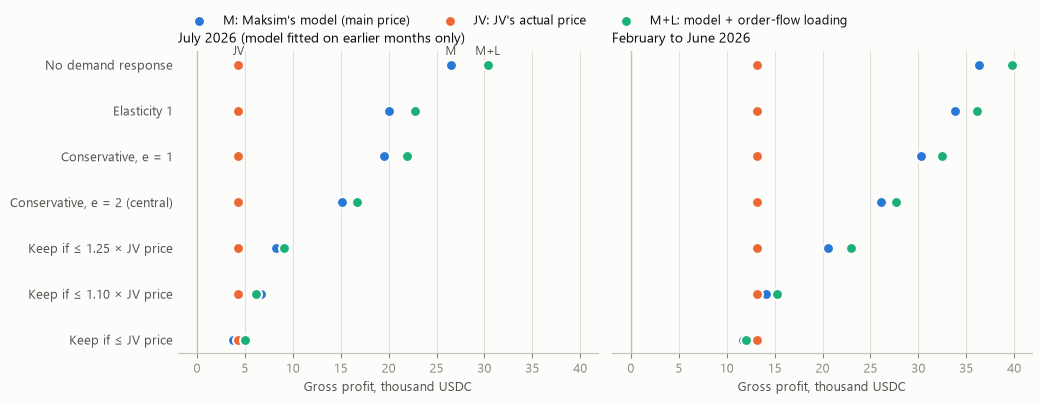


## 3. Profit on training data

Each month is priced by a model fitted only on earlier data. JV's demand rule is unknown, so we show seven rules.
"None" keeps every order. "Conservative" lets a higher price lose orders and a lower price win none. "Keep if ≤ …"
keeps an order only if our price is at most that multiple of JV's price.

| Demand rule | July: JV | July: model | Feb–Jun: JV | Feb–Jun: model |
|---|---:|---:|---:|---:|
| No demand response | 4,319 | 26,506 | 13,118 | 36,373 |
| Elasticity 1 | 4,319 | 20,018 | 13,118 | 33,846 |
| Conservative, e = 1 | 4,319 | 19,509 | 13,118 | 30,281 |
| Conservative, e = 2 (central) | 4,319 | 15,101 | 13,118 | 26,100 |
| Keep if ≤ 1.25 × JV price | 4,319 | 8,298 | 13,118 | 20,613 |
| Keep if ≤ 1.10 × JV price | 4,319 | 6,666 | 13,118 | 14,061 |
| Keep if ≤ JV price | 4,319 | 3,715 | 13,118 | 11,686 |

Difference to JV's actual price, with 90% intervals from resampling whole days:

| Period | No demand response | Conservative e = 2 |
|---|---:|---:|
| July 2026 | +22,187 (+15,472 to +29,549) | +10,782 (+3,506 to +18,719) |
| February to June 2026 | +23,255 (+13,954 to +33,115) | +12,982 (+97 to +28,592) |

Under the strictest rule ("keep only if not dearer than JV") the model makes 3,715 USDC in
July against JV's 4,319. That rule is the main commercial risk.


In [5]:
RULES = [("none", "No demand response"), ("e1", "Elasticity 1"), ("cons_e1", "Conservative, e = 1"),
         ("cons_e2", "Conservative, e = 2 (central)"), ("keep_1.25", "Keep if ≤ 1.25 × JV price"),
         ("keep_1.10", "Keep if ≤ 1.10 × JV price"), ("keep_1.00", "Keep if ≤ JV price")]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9), sharey=True, sharex=True)
y = np.arange(len(RULES))[::-1]
for ax, period, title in zip(axes, ["Jul", "Feb-Jun"], ["July 2026 (model fitted on earlier months only)", "February to June 2026"]):
    for k in ["M", "JV", "M+L"]:
        x = np.array([profit(period, k, r) for r, _ in RULES]) / 1000
        ax.scatter(x, y, s=62, color=SERIES[k], edgecolors=SURFACE, linewidths=1.5, zorder=3, label=LEG[k])
        if period == "Jul":
            ax.annotate(k, (x[0], y[0]), xytext=(0, 7), textcoords="offset points",
                        ha="center", color=INK2, fontsize=8.5)
    ax.set_yticks(y, [label for _, label in RULES])
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.axvline(0, color=AXIS, linewidth=1)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.set_title(title, loc="left", color=INK, fontsize=10)
    ax.set_xlabel("Gross profit, thousand USDC")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper left", ncol=3, frameon=False, bbox_to_anchor=(0.17, 1.04))
fig.tight_layout()
fig.savefig(FIG / "profit_by_demand_rule.png", dpi=160, bbox_inches="tight")
plt.show()

PER = {"Jul": "July", "Feb-Jun": "Feb–Jun"}
table = pd.DataFrame([{"Demand rule": label, **{f"{PER[p]}: {'JV' if k == 'JV' else 'model'}": profit(p, k, r)
                                                 for p in ["Jul", "Feb-Jun"] for k in ["JV", "M"]}}
                      for r, label in RULES])
display(Markdown(f"""
## 3. Profit on training data

Each month is priced by a model fitted only on earlier data. JV's demand rule is unknown, so we show seven rules.
"None" keeps every order. "Conservative" lets a higher price lose orders and a lower price win none. "Keep if ≤ …"
keeps an order only if our price is at most that multiple of JV's price.

{md_table(table, {c: usd for c in table.columns if c != "Demand rule"})}

Difference to JV's actual price, with 90% intervals from resampling whole days:

| Period | No demand response | Conservative e = 2 |
|---|---:|---:|
| July 2026 | {ci("Jul", "none", "M - JV")} | {ci("Jul", "cons_e2", "M - JV")} |
| February to June 2026 | {ci("Feb-Jun", "none", "M - JV")} | {ci("Feb-Jun", "cons_e2", "M - JV")} |

Under the strictest rule ("keep only if not dearer than JV") the model makes {usd(profit("Jul", "M", "keep_1.00"))} USDC in
July against JV's {usd(profit("Jul", "JV", "keep_1.00"))}. That rule is the main commercial risk.
"""))

In [6]:
lv = levels.pivot(index="strategy", columns="period", values="price_vs_jv").loc[["M", "M+L"]]
g = gini.set_index(["period", "strategy"])
rv = revealed.copy()
rv["Product"] = rv["productType"].map({1800: "30 min", 3600: "1 h", 7200: "2 h", 14400: "4 h", 28800: "8 h",
                                        43200: "12 h", 86400: "24 h"})
rv = rv[["Product", "rows", "frozen_vs_jv"]].rename(columns={"rows": "Orders", "frozen_vs_jv": "Our price ÷ JV's price"})
display(Markdown(f"""
## 4. Better pricing, not only higher pricing

JV rejects "raise every price". Three facts show that the model moves prices to where the risk is:

1. **Most orders get cheaper.** {cheaper_all:.0%} of training orders are priced below what JV charged. The model raises
   the price where JV lost money (4-hour and 8-hour products, orders between 08:00 and 12:00 UTC, release windows) and cuts
   it where JV earned a lot (30-minute products, orders between 00:00 and 04:00 UTC).
2. **The level in training is higher, but the level JV charges moved.** In training the model charges
   {lv.loc['M', 'Feb-Jun']:.3f} × JV (February to June) and {lv.loc['M', 'Jul']:.3f} × JV (July). In August, JV's own
   multiplier rose to about 1.53 × base. On the {summary['revealed_rows']} August orders where JV's price is visible, the
   model is **{summary['revealed_ratio_frozen']:.3f} × JV's price**:

{md_table(rv, {"Orders": lambda v: f"{v:,}", "Our price ÷ JV's price": lambda v: f"{v:.3f}"})}

3. **The model ranks risk.** The ordered-Lorenz Gini measures whether the orders the model marks up are the ones that
   pay out more. 0 means no ranking power. It is {g.loc[('Feb-Jun', 'M'), 'gini']:.3f} (90% interval
   {g.loc[('Feb-Jun', 'M'), 'gini_ci05']:.3f} to {g.loc[('Feb-Jun', 'M'), 'gini_ci95']:.3f}) for February to June and
   {g.loc[('Jul', 'M'), 'gini']:.3f} ({g.loc[('Jul', 'M'), 'gini_ci05']:.3f} to {g.loc[('Jul', 'M'), 'gini_ci95']:.3f}) for July.

An honest limit: under the conservative demand rule, a flat raise of JV's prices to the same total does about as well
as the model in training (Maksim's README, section 5.1). The model's case rests on what a flat raise cannot do: it
needs no JV price (JV's price is unknown for {4155 - summary['revealed_rows']:,} of the 4,155 validation orders), it ranks
risk, and it cuts the worst days.
"""))


## 4. Better pricing, not only higher pricing

JV rejects "raise every price". Three facts show that the model moves prices to where the risk is:

1. **Most orders get cheaper.** 58% of training orders are priced below what JV charged. The model raises
   the price where JV lost money (4-hour and 8-hour products, orders between 08:00 and 12:00 UTC, release windows) and cuts
   it where JV earned a lot (30-minute products, orders between 00:00 and 04:00 UTC).
2. **The level in training is higher, but the level JV charges moved.** In training the model charges
   1.166 × JV (February to June) and 1.206 × JV (July). In August, JV's own
   multiplier rose to about 1.53 × base. On the 544 August orders where JV's price is visible, the
   model is **0.957 × JV's price**:

| Product | Orders | Our price ÷ JV's price |
|---|---:|---:|
| 30 min | 106 | 0.670 |
| 1 h | 16 | 1.062 |
| 2 h | 112 | 1.021 |
| 4 h | 243 | 0.932 |
| 8 h | 65 | 1.064 |
| 12 h | 2 | 1.231 |

3. **The model ranks risk.** The ordered-Lorenz Gini measures whether the orders the model marks up are the ones that
   pay out more. 0 means no ranking power. It is 0.244 (90% interval
   0.160 to 0.314) for February to June and
   0.097 (0.041 to 0.148) for July.

An honest limit: under the conservative demand rule, a flat raise of JV's prices to the same total does about as well
as the model in training (Maksim's README, section 5.1). The model's case rests on what a flat raise cannot do: it
needs no JV price (JV's price is unknown for 3,611 of the 4,155 validation orders), it ranks
risk, and it cuts the worst days.


In [7]:
def three(period, rule):
    return {k: profit(period, k, rule) for k in ["M", "M+L", "Flat-M"]}

rows = []
for period, label in [("Jul", "July 2026"), ("Feb-Jun", "February to June 2026")]:
    for rule, rlabel in [("none", "No demand response"), ("cons_e2", "Conservative e = 2")]:
        p = three(period, rule)
        rows.append({"Period": label, "Demand rule": rlabel, "Model": p["M"], "Model + loading": p["M+L"],
                     "Flat raise, same total": p["Flat-M"]})
res = pd.DataFrame(rows)
d = summary["decision"]
mark = lambda ok: "passed" if ok else "**failed**"
lb = loading_by_month.set_index("month")
display(Markdown(f"""
## 5. The improvement we tested: Chris's order-flow loading

**The signal.** Traders often buy protection after BTC has already moved, all on the same side. JV's open book then
leans to one side, and the move partly reverses. Orders that join the crowded side pay out less than their premium;
orders that oppose it pay out more (training, book built from expiry dates only, never from `closedAt`):

{md_table(book_classes.reset_index().rename(columns={"book_class": "Order vs JV's open book", "orders": "Orders",
          "loss_ratio_at_jv_price": "Loss ratio at JV's price", "payout_over_fair_value": "Payout ÷ fair value"})
          [["Order vs JV's open book", "Orders", "Loss ratio at JV's price", "Payout ÷ fair value"]],
          {"Orders": lambda v: f"{v:,}", "Loss ratio at JV's price": lambda v: f"{v:.2f}", "Payout ÷ fair value": lambda v: f"{v:.2f}"})}

**The layer.** Premium × (1 + 0.3 × how strongly the order opposes the crowd), only when the book holds at least 1 BTC.
It never cuts a price. In July it loads {lb.loc['2026-07', 'loaded_share']:.0%} of orders by
{lb.loc['2026-07', 'mean_loading_on_loaded'] - 1:.1%} on average.

**The test.** Before any scoring, we committed a rule (`README.md`, commit `cd9437f`). The loading enters the main
price only if it beats the model in both periods and also beats a flat raise of the same size in July under the
central demand rule. The last condition separates "better" from "higher".

{md_table(res, {"Model": usd, "Model + loading": usd, "Flat raise, same total": usd})}

| Condition | Result |
|---|---|
| 1. July: loading beats the model | {mark(d['c1_july_gain'])}: {ci_words("Jul", "cons_e2", "M+L - M")}, conservative e = 2 |
| 2. February to June: loading beats the model | {mark(d['c2_febjun_gain'])}: {ci_words("Feb-Jun", "cons_e2", "M+L - M")} |
| 3. July: loading beats a flat raise of the same size | {mark(d['c3_july_beats_flat'])}: {ci_words("Jul", "cons_e2", "M+L - Flat-M")} |

**Decision: the loading stays out of the main price.** We cannot show that its gain comes from better
allocation rather than from the higher price level. The file keeps it as an option: `premium_frozen_model_USDC × orderflow_loading`. With it, the validation
total would be {usd(summary['premium_total_with_loading'])} USDC (+{summary['premium_total_with_loading'] / summary['premium_total_frozen'] - 1:.1%}),
still {summary['revealed_ratio_with_loading']:.3f} × JV's revealed August price. The signal itself is strongest as a
**risk** signal: it explains why the exposure cap is needed (section 6).
"""))


## 5. The improvement we tested: Chris's order-flow loading

**The signal.** Traders often buy protection after BTC has already moved, all on the same side. JV's open book then
leans to one side, and the move partly reverses. Orders that join the crowded side pay out less than their premium;
orders that oppose it pay out more (training, book built from expiry dates only, never from `closedAt`):

| Order vs JV's open book | Orders | Loss ratio at JV's price | Payout ÷ fair value |
|---|---:|---:|---:|
| book under 1 BTC | 3,676 | 0.81 | 0.94 |
| joins the crowd | 898 | 0.69 | 0.77 |
| neutral | 1,968 | 1.11 | 1.08 |
| opposes the crowd | 608 | 1.12 | 1.12 |

**The layer.** Premium × (1 + 0.3 × how strongly the order opposes the crowd), only when the book holds at least 1 BTC.
It never cuts a price. In July it loads 31% of orders by
6.1% on average.

**The test.** Before any scoring, we committed a rule (`README.md`, commit `cd9437f`). The loading enters the main
price only if it beats the model in both periods and also beats a flat raise of the same size in July under the
central demand rule. The last condition separates "better" from "higher".

| Period | Demand rule | Model | Model + loading | Flat raise, same total |
|---|---|---:|---:|---:|
| July 2026 | No demand response | 26,506 | 30,347 | 30,347 |
| July 2026 | Conservative e = 2 | 15,101 | 16,696 | 16,812 |
| February to June 2026 | No demand response | 36,373 | 39,816 | 39,816 |
| February to June 2026 | Conservative e = 2 | 26,100 | 27,719 | 27,681 |

| Condition | Result |
|---|---|
| 1. July: loading beats the model | passed: +1,596 USDC (90% interval +692 to +2,610), conservative e = 2 |
| 2. February to June: loading beats the model | passed: +1,619 USDC (90% interval +794 to +2,494) |
| 3. July: loading beats a flat raise of the same size | **failed**: -116 USDC (90% interval -1,015 to +738) |

**Decision: the loading stays out of the main price.** We cannot show that its gain comes from better
allocation rather than from the higher price level. The file keeps it as an option: `premium_frozen_model_USDC × orderflow_loading`. With it, the validation
total would be 211,553 USDC (+2.8%),
still 0.978 × JV's revealed August price. The signal itself is strongest as a
**risk** signal: it explains why the exposure cap is needed (section 6).


In [8]:
risk = pd.DataFrame([{"Price": NAME[k], "Worst day, no demand response": metric("Feb-Jul", k, "none", "worst_day"),
                      "Worst day, conservative e = 2": metric("Feb-Jul", k, "cons_e2", "worst_day"),
                      "Largest drawdown, no demand response": metric("Feb-Jul", k, "none", "max_drawdown")}
                     for k in ["JV", "M"]])
ct = caps[caps["sample"].str.startswith("training")].copy()
ct["Rule"] = np.where(ct["cap_per_direction_USDC"].isna(), "No cap",
                      ct["cap_per_direction_USDC"].map(lambda v: f"Cap {v:,.0f} USDC" if v == v else ""))
ct.loc[ct["policy"].notna(), "Rule"] = "Cap 250,000 + BTC hedge within 0.5 BTC"
ct = ct[["Rule", "profit", "premium_rejected_share", "worst_day", "max_drawdown"]].rename(columns={
    "profit": "Profit", "premium_rejected_share": "Premium turned away", "worst_day": "Worst day",
    "max_drawdown": "Largest drawdown"})
cb = cap_blind.rename(columns={"month": "Month", "orders": "Orders", "paused_share": "Orders paused",
                               "premium_paused_share": "Premium paused"})
display(Markdown(f"""
## 6. Risk: cap the open exposure, do not just raise the price

JV's gain on an order is capped at the premium; its loss is not. Losses come in a few days when BTC trends and the
crowd is right. No price set at the time of the order can foresee those days. The model already lowers the worst day
(training, February to July):

{md_table(risk, {c: usd for c in risk.columns if c != "Price"})}

**Maksim's exposure cap** pauses new sales in one direction while the open protected notional in that direction is
above the cap. Training trade-off (Maksim's file `results/extensions/exposure_limits.csv`, profit with no demand
response, USDC):

{md_table(ct, {"Profit": usd, "Premium turned away": lambda v: f"{v:.0%}", "Worst day": usd, "Largest drawdown": usd})}

On the validation orders, counting each protection until its expiry, the 250,000 USDC cap would pause:

{md_table(cb, {"Orders": lambda v: f"{v:,.0f}", "Orders paused": lambda v: f"{v:.1%}", "Premium paused": lambda v: f"{v:.1%}"})}

The cap size is JV's risk appetite. It limits a month like August 2026; it does not prevent it. A hedge updated every
minute was also tested; its fees cost more than it saved (Maksim's README, section 7.1).
"""))


## 6. Risk: cap the open exposure, do not just raise the price

JV's gain on an order is capped at the premium; its loss is not. Losses come in a few days when BTC trends and the
crowd is right. No price set at the time of the order can foresee those days. The model already lowers the worst day
(training, February to July):

| Price | Worst day, no demand response | Worst day, conservative e = 2 | Largest drawdown, no demand response |
|---|---:|---:|---:|
| JV's actual price | -9,630 | -9,630 | 13,031 |
| Maksim's model (main price) | -7,636 | -2,687 | 9,673 |

**Maksim's exposure cap** pauses new sales in one direction while the open protected notional in that direction is
above the cap. Training trade-off (Maksim's file `results/extensions/exposure_limits.csv`, profit with no demand
response, USDC):

| Rule | Profit | Premium turned away | Worst day | Largest drawdown |
|---|---:|---:|---:|---:|
| No cap | 62,879 | 0% | -8,399 | 10,688 |
| Cap 400,000 USDC | 61,653 | 2% | -8,399 | 10,688 |
| Cap 250,000 USDC | 55,753 | 15% | -6,594 | 9,326 |
| Cap 150,000 USDC | 44,168 | 34% | -4,814 | 6,844 |
| Cap 250,000 + BTC hedge within 0.5 BTC | 44,194 | 15% | -3,976 | 7,815 |

On the validation orders, counting each protection until its expiry, the 250,000 USDC cap would pause:

| Month | Orders | Orders paused | Premium paused |
|---|---:|---:|---:|
| 2026-07 | 118 | 0.0% | 0.0% |
| 2026-08 | 2,129 | 7.3% | 30.5% |
| 2026-09 | 1,340 | 13.5% | 30.4% |
| 2026-10 | 568 | 9.9% | 26.3% |

The cap size is JV's risk appetite. It limits a month like August 2026; it does not prevent it. A hedge updated every
minute was also tested; its fees cost more than it saved (Maksim's README, section 7.1).


In [9]:
wf = wf_monthly[wf_monthly["scenario"].isin(["elasticity=0", "conservative_elasticity=2"])]
wf = wf.pivot_table(index="month", columns=["scenario", "strategy"], values="profit")
wf = pd.DataFrame({"Month": wf.index,
                   "JV, no demand response": wf[("elasticity=0", "current price (base + CTA markup)")].to_numpy(),
                   "Model, no demand response": wf[("elasticity=0", "model")].to_numpy(),
                   "JV, conservative e = 2": wf[("conservative_elasticity=2", "current price (base + CTA markup)")].to_numpy(),
                   "Model, conservative e = 2": wf[("conservative_elasticity=2", "model")].to_numpy()})
cal = calib[calib["group_by"] == "month"].rename(columns={"group": "Month"})[["Month", "payout_over_fair_value"]]
wf = wf.merge(cal, on="Month").rename(columns={"payout_over_fair_value": "Payout ÷ fair value"})
sm = sealed_monthly.rename(columns={"month": "Month", "orders": "Orders", "premium": "Premium", "payout": "Payout",
                                    "profit": "Profit", "loss_ratio": "Loss ratio"})[["Month", "Orders", "Premium",
                                                                                    "Payout", "Profit", "Loss ratio"]]
display(Markdown(f"""
## 7. Performance on unseen data

**Walk-forward on training data.** Each month is priced by a model fitted only on earlier months. The model makes more
than JV in every month with no demand response. "Payout ÷ fair value" near 1 means the fair value is calibrated:

{md_table(wf, {c: usd for c in wf.columns if c not in ("Month", "Payout ÷ fair value")} | {"Payout ÷ fair value": lambda v: f"{v:.2f}"})}

**One sealed check on the validation period.** Maksim froze and pushed the price file first (commit `c70c413`,
14 Oct 2026). With the team's agreement, he then rebuilt the hidden payouts **once**, for an aggregate check. No price
changed after it, and no part of this final solution was tuned on it:

{md_table(sm, {"Orders": lambda v: f"{v:,.0f}", "Premium": usd, "Payout": usd, "Profit": usd, "Loss ratio": lambda v: f"{v:.2f}"})}

Over the whole period payouts were {sealed['payout_over_fair_value_all']:.2f} × fair value. August was hard for every
price: BTC rose 25%, so protection for short positions paid far more than usual. On the 544 orders where JV's own price
is visible, JV's price also lost money (−26,119 USDC against the model's −27,684).
"""))


## 7. Performance on unseen data

**Walk-forward on training data.** Each month is priced by a model fitted only on earlier months. The model makes more
than JV in every month with no demand response. "Payout ÷ fair value" near 1 means the fair value is calibrated:

| Month | JV, no demand response | Model, no demand response | JV, conservative e = 2 | Model, conservative e = 2 | Payout ÷ fair value |
|---|---:|---:|---:|---:|---:|
| 2026-02 | -453 | -166 | -453 | -257 | 1.41 |
| 2026-03 | 49 | 129 | 49 | 247 | 1.12 |
| 2026-04 | 2,645 | 4,097 | 2,645 | 2,454 | 0.85 |
| 2026-05 | 4,620 | 9,800 | 4,620 | 6,074 | 0.85 |
| 2026-06 | 6,257 | 22,514 | 6,257 | 17,582 | 1.01 |
| 2026-07 | 4,319 | 26,506 | 4,319 | 15,101 | 1.00 |

**One sealed check on the validation period.** Maksim froze and pushed the price file first (commit `c70c413`,
14 Oct 2026). With the team's agreement, he then rebuilt the hidden payouts **once**, for an aggregate check. No price
changed after it, and no part of this final solution was tuned on it:

| Month | Orders | Premium | Payout | Profit | Loss ratio |
|---|---:|---:|---:|---:|---:|
| 2026-07 | 118 | 49 | 51 | -2 | 1.04 |
| 2026-08 | 2,129 | 86,266 | 98,933 | -12,667 | 1.15 |
| 2026-09 | 1,340 | 90,144 | 79,332 | 10,812 | 0.88 |
| 2026-10 | 568 | 29,365 | 22,687 | 6,679 | 0.77 |

Over the whole period payouts were 1.23 × fair value. August was hard for every
price: BTC rose 25%, so protection for short positions paid far more than usual. On the 544 orders where JV's own price
is visible, JV's price also lost money (−26,119 USDC against the model's −27,684).


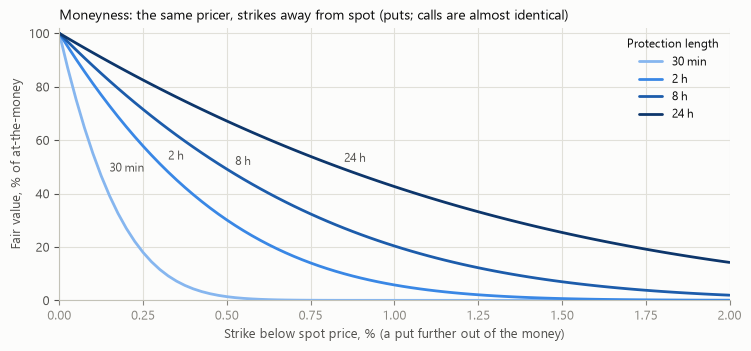


## 8. Market conditions and moneyness

**Market conditions** enter through the expected move: recent volatility over four horizons, the time of day in
New York time (variance after the 09:30 equity open is 3.8 × the weekly average), and scheduled US releases. JV's
base price ignores the time of day.

**Moneyness.** Every order in the data is at the money, so no outcome can test other strikes. The pricer handles them
by construction: the same Black-Scholes formula prices a strike away from spot, with the same 25% margin. Protection
with a short duration loses its value fastest when the strike moves away:

| Protection length | At the money | 0.25% out of the money | 0.50% out of the money | 1.00% out of the money | 2.00% out of the money |
|---|---:|---:|---:|---:|---:|
| 30 min | 100% | 18% | 1% | 0% | 0% |
| 1 h | 100% | 51% | 22% | 2% | 0% |
| 2 h | 100% | 58% | 30% | 6% | 0% |
| 4 h | 100% | 66% | 41% | 13% | 1% |
| 8 h | 100% | 72% | 49% | 20% | 2% |
| 12 h | 100% | 75% | 54% | 26% | 4% |
| 24 h | 100% | 82% | 67% | 43% | 14% |

So the case's question "should ATM and OTM protection use the same markup?" has a clear answer here: the same margin
on fair value, because the fair value already falls with distance and with shorter protection.


In [10]:
fine = np.linspace(0, 0.02, 81)
RAMP = {1800: ("30 min", "#86b6ef"), 7200: ("2 h", "#3987e5"), 28800: ("8 h", "#1c5cab"), 86400: ("24 h", "#0d366b")}
fig, ax = plt.subplots(figsize=(7.6, 3.6))
for dur, (label, color) in RAMP.items():
    g = frozen[frozen["productType"] == dur]
    put = s.moneyness_table(g["expected_abs_move_bps"].median() / 1e4, float(g["strikePrice"].median()), fine)
    put = put[put["side"] == "put"]
    x, v = put["otm_distance"].to_numpy() * 100, put["vs_at_the_money"].to_numpy() * 100
    ax.plot(x, v, color=color, linewidth=2, solid_capstyle="round", label=label)
    i = int(np.argmin(np.abs(v - 50)))
    ax.annotate(label, (x[i], v[i]), xytext=(6, 3), textcoords="offset points", color=INK2, fontsize=8.5)
ax.set_xlim(0, 2)
ax.set_ylim(0, 102)
ax.set_xlabel("Strike below spot price, % (a put further out of the money)")
ax.set_ylabel("Fair value, % of at-the-money")
ax.grid(color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(title="Protection length", frameon=False, loc="upper right", title_fontsize=8.5, fontsize=8.5)
ax.set_title("Moneyness: the same pricer, strikes away from spot (puts; calls are almost identical)",
             loc="left", fontsize=10, color=INK)
fig.tight_layout()
fig.savefig(FIG / "moneyness_put.png", dpi=160, bbox_inches="tight")
plt.show()

mt = moneyness[moneyness["side"] == "put"].pivot_table(index="productType", columns="otm_distance", values="vs_at_the_money")
mt = mt.reset_index()
mt["productType"] = mt["productType"].map({1800: "30 min", 3600: "1 h", 7200: "2 h", 14400: "4 h", 28800: "8 h",
                                           43200: "12 h", 86400: "24 h"})
mt.columns = ["Protection length"] + [f"{c * 100:.2f}% out of the money" if c else "At the money" for c in mt.columns[1:]]
display(Markdown(f"""
## 8. Market conditions and moneyness

**Market conditions** enter through the expected move: recent volatility over four horizons, the time of day in
New York time (variance after the 09:30 equity open is 3.8 × the weekly average), and scheduled US releases. JV's
base price ignores the time of day.

**Moneyness.** Every order in the data is at the money, so no outcome can test other strikes. The pricer handles them
by construction: the same Black-Scholes formula prices a strike away from spot, with the same 25% margin. Protection
with a short duration loses its value fastest when the strike moves away:

{md_table(mt, {c: (lambda v: f"{v:.0%}") for c in mt.columns if c != "Protection length"})}

So the case's question "should ATM and OTM protection use the same markup?" has a clear answer here: the same margin
on fair value, because the fair value already falls with distance and with shorter protection.
"""))

In [11]:
mg = margins[margins["scenario"].isin(["no demand response", "conservative_elasticity=1", "keep_if_within_0pct"])]
mg = mg[mg["margin"].isin([0.10, 0.20, 0.25, 0.30, 0.40])]
mg = mg.pivot_table(index="margin", columns="scenario", values="profit").join(
    margins[margins["scenario"] == "conservative_elasticity=1"].set_index("margin")[["orders_vs_today", "current_premium_retained"]])
mg = mg.reset_index()
mg.columns = ["Margin on fair value", "Conservative e = 1", "Keep if not dearer", "No demand response",
              "Orders kept (cons. e = 1)", "JV premium kept (cons. e = 1)"]
mg = mg[["Margin on fair value", "No demand response", "Conservative e = 1", "Keep if not dearer",
         "Orders kept (cons. e = 1)", "JV premium kept (cons. e = 1)"]]
display(Markdown(f"""
## 9. The margin is a business choice

Under the smooth and conservative demand rules, a higher margin always looks more profitable in training. That is exactly the "just
raise prices" trap JV warns about: our data holds only orders that were bought, so it cannot measure how many traders
a higher price drives away. Maksim set 25% before any test at that margin. We keep it. (February to July, walk-forward,
gross profit in USDC.)

{md_table(mg, {"Margin on fair value": lambda v: f"{v:.0%}", "No demand response": usd, "Conservative e = 1": usd,
               "Keep if not dearer": usd, "Orders kept (cons. e = 1)": lambda v: f"{v:.0%}",
               "JV premium kept (cons. e = 1)": lambda v: f"{v:.0%}"})}

A 25% margin is also the best margin for a seller whose buyers have a constant price elasticity of 5
(Lerner rule: P = cost × e ÷ (e − 1) = 1.25 × cost). JV can measure its real elasticity with a small randomised price
test, for example ±10% on a random 10% of quotes.
"""))


## 9. The margin is a business choice

Under the smooth and conservative demand rules, a higher margin always looks more profitable in training. That is exactly the "just
raise prices" trap JV warns about: our data holds only orders that were bought, so it cannot measure how many traders
a higher price drives away. Maksim set 25% before any test at that margin. We keep it. (February to July, walk-forward,
gross profit in USDC.)

| Margin on fair value | No demand response | Conservative e = 1 | Keep if not dearer | Orders kept (cons. e = 1) | JV premium kept (cons. e = 1) |
|---:|---:|---:|---:|---:|---:|
| 10% | 28,758 | 25,213 | 12,071 | 93% | 89% |
| 20% | 51,383 | 41,974 | 13,544 | 91% | 85% |
| 25% | 62,879 | 49,790 | 15,401 | 90% | 84% |
| 30% | 74,434 | 57,198 | 16,104 | 88% | 82% |
| 40% | 97,665 | 70,794 | 15,471 | 86% | 78% |

A 25% margin is also the best margin for a seller whose buyers have a constant price elasticity of 5
(Lerner rule: P = cost × e ÷ (e − 1) = 1.25 × cost). JV can measure its real elasticity with a small randomised price
test, for example ±10% on a random 10% of quotes.


In [12]:
display(Markdown(f"""
## 10. Practical use

- **Inputs:** 1-minute BTC candles, a public calendar of US releases, and (for the cap and the loading) JV's own open
  book. No order outcome enters the model.
- **One setting:** the margin. The base-price floor and the cap are simple rules.
- **Deployment:** the model runs off-chain from an oracle price feed and publishes a quote; the cap is a counter per
  direction (Blockchain lectures 6–7: off-chain model, oracle, limits).
- **Reproducible:** `final_solution.ipynb` rebuilds `outputs/` from the team's saved files; `tests/` holds
  {28} automatic checks, including one that changes every `closedAt` value and gets the same prices.

## 11. Tested and not adopted

| Idea | Who | Why not |
|---|---|---|
| Order-flow loading in the main price | Chris | Not better than a flat raise of the same size (section 5); kept as an option |
| Locked F1 (θ = 0) | Aman | Below JV's profit in July under every demand rule; its level comes from an estimate of JV's price that ran 12% low in July |
| Hybrid as the main model | Subham | Its own "base × one constant" benchmark makes more; settings chosen on the months it reports; 53% of validation orders need a rebuilt base |
| News, social sentiment, LLM event research | Jay | No measurable gain at 30-minute to 24-hour horizons once the release calendar is in |
| Order size, direction, volatility regimes, range and volume features, US holidays | Maksim | Failed rules written before testing, or unstable over time |
| Hedge updated every minute | Maksim | Fees cost more than it saved on the validation period |
| A higher margin | – | Looks better only because demand is assumed; would be tuned after the August check |

## 12. Limitations

1. **Demand was not estimated.** All demand rules are assumptions; JV's rule is unknown. Under "keep only if not dearer
   than JV" the model does not beat JV in July.
2. **Trending months can lose at any price.** August 2026 lost money for the model and for JV's own prices. The cap
   limits such months; no price set at the time of the order prevents them.
3. **Data disclosure.** The validation file still contains `closedAt`, and its candles run to 14 October, so the hidden
   outcomes can be rebuilt. No model used them as an input; the team ran one agreed aggregate check after freezing the
   prices and changed no price afterwards. JV may want to blank `closedAt` in future releases.
4. **Gross underwriting profit only.** Fees, funding and capital costs are not included.
5. **Small segments.** 12-hour, 24-hour and release-window orders are tens to a few hundred orders. A handful of days
   and about 1% of orders drive monthly profit.

## 13. Files

| File | Content |
|---|---|
| `outputs/final_submission.csv` | {summary['rows']:,} rows in the original order. Main column `recommended_premium_USDC`; `recommended_multiplier_vs_base` (blank without a base price); `fair_value_USDC`; `premium_frozen_model_USDC`; `orderflow_loading` (the option). SHA-256 `{summary['submission_sha256'][:16]}…` |
| `outputs/summary.json` | Totals, checks, the adoption decision, input hashes |
| `outputs/*.csv`, `outputs/figures/` | Every table and chart in this report |
| `final_solution.ipynb`, `solution.py`, `tests/` | The computation, its functions and 28 checks |
| `README.md` | The adoption rule (committed before scoring) and run steps |
"""))


## 10. Practical use

- **Inputs:** 1-minute BTC candles, a public calendar of US releases, and (for the cap and the loading) JV's own open
  book. No order outcome enters the model.
- **One setting:** the margin. The base-price floor and the cap are simple rules.
- **Deployment:** the model runs off-chain from an oracle price feed and publishes a quote; the cap is a counter per
  direction (Blockchain lectures 6–7: off-chain model, oracle, limits).
- **Reproducible:** `final_solution.ipynb` rebuilds `outputs/` from the team's saved files; `tests/` holds
  28 automatic checks, including one that changes every `closedAt` value and gets the same prices.

## 11. Tested and not adopted

| Idea | Who | Why not |
|---|---|---|
| Order-flow loading in the main price | Chris | Not better than a flat raise of the same size (section 5); kept as an option |
| Locked F1 (θ = 0) | Aman | Below JV's profit in July under every demand rule; its level comes from an estimate of JV's price that ran 12% low in July |
| Hybrid as the main model | Subham | Its own "base × one constant" benchmark makes more; settings chosen on the months it reports; 53% of validation orders need a rebuilt base |
| News, social sentiment, LLM event research | Jay | No measurable gain at 30-minute to 24-hour horizons once the release calendar is in |
| Order size, direction, volatility regimes, range and volume features, US holidays | Maksim | Failed rules written before testing, or unstable over time |
| Hedge updated every minute | Maksim | Fees cost more than it saved on the validation period |
| A higher margin | – | Looks better only because demand is assumed; would be tuned after the August check |

## 12. Limitations

1. **Demand was not estimated.** All demand rules are assumptions; JV's rule is unknown. Under "keep only if not dearer
   than JV" the model does not beat JV in July.
2. **Trending months can lose at any price.** August 2026 lost money for the model and for JV's own prices. The cap
   limits such months; no price set at the time of the order prevents them.
3. **Data disclosure.** The validation file still contains `closedAt`, and its candles run to 14 October, so the hidden
   outcomes can be rebuilt. No model used them as an input; the team ran one agreed aggregate check after freezing the
   prices and changed no price afterwards. JV may want to blank `closedAt` in future releases.
4. **Gross underwriting profit only.** Fees, funding and capital costs are not included.
5. **Small segments.** 12-hour, 24-hour and release-window orders are tens to a few hundred orders. A handful of days
   and about 1% of orders drive monthly profit.

## 13. Files

| File | Content |
|---|---|
| `outputs/final_submission.csv` | 4,155 rows in the original order. Main column `recommended_premium_USDC`; `recommended_multiplier_vs_base` (blank without a base price); `fair_value_USDC`; `premium_frozen_model_USDC`; `orderflow_loading` (the option). SHA-256 `810eae3a1c007c94…` |
| `outputs/summary.json` | Totals, checks, the adoption decision, input hashes |
| `outputs/*.csv`, `outputs/figures/` | Every table and chart in this report |
| `final_solution.ipynb`, `solution.py`, `tests/` | The computation, its functions and 28 checks |
| `README.md` | The adoption rule (committed before scoring) and run steps |
